<a href="https://colab.research.google.com/github/aregueiraaraujo/Data-Analytics/blob/main/Sprint%208/Sprint_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Algoritmo:
- Importar las librerias y los archivos necesários para todos los ejercicios de los niveles

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
from sklearn.impute import KNNImputer
from IPython.display import display

# Importación de la base de datos y creación del DataFrame de empleados.
empleados = pd.read_excel("/content/sprint8_complex.xlsx", skiprows=3, header=0,)
empleados.rename(columns ={'Unnamed: 0': 'Id'}, inplace = True)

# Importación de la base de datos de la politica salarial.
politica = pd.read_json("/content/politica_salarial.json")

# Importación de la base de datos del contexto de las ciudades.
ciudades = pd.read_csv("/content/ciutats_context.csv", encoding="cp1252")

# Importación de la base de datos de las distáncias.
distancias = pd.read_excel("/content/matriu_distancies.xlsx")

#Nivel 1

Ejercicio 1: Exploración inicial del dataset

Algoritmo:
- Imprimir una muestra aleatoria del DataFrame;
- Identificar cuántos DNI están repetidos y cuáles son;
- Identificar posibles problemas de lectura o inconsistencias en los datos.

In [64]:
# Esta función muestra el tipo de datos contenido en cada columna, calcula y
# imprime los DNI repetidos y su recuento, y retorna una muestra aleatoria del
# conjunto de datos.
def verificar_dataset(df):

  res = df.sample(frac=1).reset_index(drop=True)
  print("---------- Tipos de datos -----------")
  print(df.dtypes,"\n")

  print("---- DNI repetidos ----")
  duplicadas = df[df.duplicated(['DNI'], keep=False)]
  print(duplicadas["DNI"].value_counts().reset_index(name="Cantidad"))

  return res

tabla_empleados = verificar_dataset(empleados)

display(tabla_empleados.head(5).style.set_caption("Empleados"))

# Los datos parecen coherentes pero hay problmeas con datos faltantes y caracteres
# especiales como ¨,´,~... que causan errores de lectura como  "SchrÃ¶der". Otro pproblema es el
# formato de algunos datos como por ejemplo las fehcas e años están como Float cuándo
# deberían ser Date.

---------- Tipos de datos -----------
Id                              int64
Nom                            object
Cognoms                        object
DNI                            object
País d'origen                  object
Ciutat                         object
Dia de Naixement              float64
Mes de Naixement              float64
Any de Naixement              float64
Gènere                         object
Salari mensual                 object
Fills                          object
No Fills                       object
Grup Professional              object
CÃ rrec                        object
Nombre_fills                  float64
Te_cotxe                       object
Km_anuals                     float64
Consum_mitja_L_100km          float64
Temperatura_mitjana_ciutat    float64
dtype: object 

---- DNI repetidos ----
         DNI  Cantidad
0  90585882A         6
1  16618423V         4
2  55283701C         2
3  15909601K         2
4  54013571W         2
5  97954019T         2
6

,Id,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,725,Maja,Nilsen,62978421F,Noruega,Bergen,4.000000,12.000000,1978.000000,H,796â‚¬,nan,True,Grup A,Data Analyst,nan,True,114489.000000,10.000000,9.500000
1,547,Marina,Ãlvarez,50531871J,Espanya,Alacant,24.000000,11.000000,1979.000000,F,1025â‚¬,nan,True,Grup A,TÃ¨cnic IT,nan,True,74741.000000,25.000000,18.500000
2,79,Oriol,Ramos,62780072Q,Espanya,ValÃ¨ncia,3.000000,1.000000,1989.000000,H,"3,063 â‚¬",True,nan,Grup D,Responsable de vendes,4.000000,nan,nan,nan,18.100000
3,462,NÃºria,Vidal,48066060L,Espanya,Sevilla,13.000000,2.000000,1993.000000,H,"1,047 â‚¬",nan,True,Grup A,Senior analyst,0.000000,nan,nan,nan,17.600000
4,3,Pol,Gil,58586340F,Espanya,Sevilla,13.000000,10.000000,1985.000000,H,"1,478 â‚¬",True,nan,Grup B,Data Analyst,2.000000,False,nan,nan,18.300000


Algoritmo:
- Crear funciones para modificar el formato de visualización de los datos, eliminar filas duplicadas, corregir datos inconsistentes y eliminar filas cuyos datos carezcan de sentido.
- Crear una función principal para orquestar las demás.

- Ejercicio 2: Validaciones básicas de los datos y decisiones de eliminación

  Y


- Ejercicio 3: Transformaciones necesarias y preparación del dataset

In [65]:
# Esta función encuentra y elimina filas duplicadas utilizando el DNI como clave primaria
# muestra cuántas filas se eliminaron y devuelve el dataframe limpio.
def eliminar_DNI_duplicados(df):

  print("Eliminar DNI duplicados:")
  duplicadas = df[df.duplicated(subset=["DNI"], keep=False)]
  if len(duplicadas) > 0:
    colunas_validacion = list(df.columns[1:19])
    todas_colunas = ["DNI"] + colunas_validacion
    df_limpio = df.drop_duplicates(subset=todas_colunas, keep='first')
    df_final = df_limpio[~df_limpio.duplicated(subset=["DNI"], keep=False)]

    print(f"Filas originales: {len(df)}")
    print(f"Filas eliminadas: {len(df) - len(df_final)}")
    print(f"Filas após limpieza: {len(df_final)}\n")
  else:
    print("No hay filas duplicadas.\n")

  return df_final

# Esta función busca campos vacíos o con XXXX en la columna DNI y elimina las
# líneas correspondientes, ya que sin un DNI válido no debe haber un registro válido.
def eliminar_DNI_vacio(df):

  print("Eliminar DNI vacíos:")
  tamano_original = len(df)
  df['DNI'] = df['DNI'].replace(['',"XXXX"], np.nan)
  df = df.dropna(subset=['DNI'])
  if tamano_original != len(df):
    print(f"Filas originales:", tamano_original)
    print(f"Filas eliminadas: {tamano_original - len(df)}")
    print(f"Filas após limpieza:{len(df)}\n")
  else:
    print("No hay DNI vacíos o iguales a XXXX.\n")

  return df

# Esta función verifica si todos los DNI están compuestos por 8 números y una letra
# al final; de lo contrario, elimina la línea.
def eliminar_DNI_invalido(df):

  print("Eliminar DNI inválidos:")
  tamano_original = len(df)
  df_DNI_tamano = df["DNI"].str.len() <= 9
  df_DNI_fin_letra = df["DNI"].str[-1].str.isalpha() == True
  df = df[df_DNI_tamano & df_DNI_fin_letra]
  if len(df) == tamano_original:
    print("No hay DNIs invalidos.\n")
  else:
    print(f"Filas originales:", tamano_original)
    print(f"Filas eliminadas: {tamano_original - len(df)}")
    print(f"Filas após limpieza: {len(df)}\n")

  return df

# Esta función convierte todo el texto del dataframe de cp1252 a utf-8 con la ayuda
# de la función encoding(). De esta forma, se eliminan problemas con caracteres como (¨, ´, ~...)
def verif_palabras(df):

  tamano_original = len(df)
  df.rename(columns = encoding, inplace=True)
  columnas_a_arreglar = ["Nom", "Cognoms", "País d'origen", "Ciutat", "Salari mensual", "Càrrec"]

  for columna in columnas_a_arreglar:
        if columna in df.columns:
            df[columna] = df[columna].apply(encoding)

  return df

# Esta función auxiliar convierte el texto de las columnas modificadas por la función
# verif_palabras() y garantiza que los campos vacíos no provoquen un error.
def encoding(texto):

  if pd.isna(texto) or not isinstance(texto, str):
      return texto
  try:
      return texto.encode('cp1252').decode('utf-8')
  except (UnicodeEncodeError, UnicodeDecodeError, AttributeError):
      return texto

# Esta función busca filas vacías en la columna Nom y las elimina, ya que
# no debe haber ningún registro sin nombre.
def verif_nombres(df):

  print("Eliminar Nombres vacíos:")
  tamano_original = len(df)
  df['Nom'] = df['Nom'].replace([''], np.nan)
  df = df.dropna(subset=['Nom'])
  if tamano_original != len(df):
    print(f"Filas originales:", tamano_original)
    print(f"Filas eliminadas: {tamano_original - len(df)}")
    print(f"Filas após limpieza:{len(df)}\n")
  else:
    print("No hay Nombres vacíos.\n")

  return df

# Esta función verifica si las fechas son coherentes, si se encuentran dentro de un intervalo
# de años, meses y días plausible.
def verif_fechas(df):

  columnas_fecha = ["Dia de Naixement", "Mes de Naixement", "Any de Naixement"]
  df[columnas_fecha] = df[columnas_fecha].astype('Int64')

  print("Eliminar fechas incorrectas:")
  tamano_original = len(df)

  df_ano = df["Any de Naixement"].between(1926, 2008)

  datas_calculadas = pd.to_datetime({'year': df["Any de Naixement"], 'month': df["Mes de Naixement"], 'day': df["Dia de Naixement"]}, errors='coerce')

  df_data_valida = datas_calculadas.notna()

  df = df[df_ano & df_data_valida]

  if tamano_original != len(df):
      print(f"Filas originales: {tamano_original}")
      print(f"Filas eliminadas: {tamano_original - len(df)}")
      print(f"Filas após limpieza: {len(df)}\n")
  else:
      print("No hay fechas incorrectas.\n")

  return df

# Esta función estandariza el género en Home y Dona, evitando datos con valores
# diferentes para el mismo significado.
def verif_genero(df):

  df = df.copy()
  df["Gènere"] = df["Gènere"].str.strip().str.upper()
  df["Gènere"] = df["Gènere"].replace({"H": "HOME", "M": "HOME", "F": "DONA", "D": "DONA"})
  df["Gènere"] = df["Gènere"].str.capitalize()

  return df

# Esta función estandariza el formato de la moneda y añade los valores faltantes
# según agrupaciones por franja de edad, grupo profesional, cargo y ciudad.
def verif_sal(df):

  df = df.copy()
  df["Salari mensual"] = df["Salari mensual"].str.replace("euros", "")
  df["Salari mensual"] = df["Salari mensual"].str.replace("€", "")
  df["Salari mensual"] = df["Salari mensual"].str.replace("dos mil", "2000")
  df["Salari mensual"] = df["Salari mensual"].str.replace("mil vuit-cents", "1800")
  df["Salari mensual"] = df["Salari mensual"].str.replace("tres mil", "3000")
  df["Salari mensual"] = df["Salari mensual"].replace("n/d", np.nan)
  df["Salari mensual"] = df["Salari mensual"].str.replace(",", "").str.strip()
  df["Salari mensual"] = pd.to_numeric(df["Salari mensual"], errors="coerce")

  ano_atual = datetime.datetime.now().year
  df["Edad"] = ano_atual - df["Any de Naixement"]
  limites = [17, 30, 50, 80]
  franjas = ["18 a 30", "31 a 50", "51 a 80"]
  df["Franja_edad"] = pd.cut(df["Edad"], bins = limites, labels = franjas)
  df["Salari mensual"] = df["Salari mensual"].fillna(df.groupby(["Càrrec", "Grup Professional", "Ciutat", "Franja_edad"])["Salari mensual"].transform("median"))
  df["Salari mensual"] = df["Salari mensual"].fillna(df.groupby(["Càrrec", "Grup Professional", "Franja_edad"])["Salari mensual"].transform("median"))
  df["Salari mensual"] = df["Salari mensual"].fillna(df.groupby(["Càrrec", "Grup Professional"])["Salari mensual"].transform("median"))
  df["Salari mensual"] = df["Salari mensual"].fillna(df.groupby("Càrrec")["Salari mensual"].transform("median"))
  df["Salari mensual"] = df["Salari mensual"].round(2)
  df = df.drop(columns=["Edad", "Franja_edad"])

  return df

# Esta función elimina nas columnas Fills y No Fills porque no hay datos significativos
# en ellas y modifica el tipo de float a Int para la columna Nombre_fills.
def verif_hijos(df):

  df = df.copy()
  df = df.drop(columns=["Fills", "No Fills"], errors="ignore")
  df["Nombre_fills"] = df["Nombre_fills"].astype("Int64")

  return df

# Esta función convierte posibles valores negativos en positivos para Km_anuals
# y utiliza la función k-Nearest Neighbors para encontrar, a partir de la tendencia de los datos
# más cercanos, un valor de Km_anuals correspondiente según Consum_mitja_L_100km.
# Si la columna Te_cotxe es false, los valores de Km_anuals y Consum_mitja_L_100km
# se vuelven iguales a 0.
import numpy as np
from sklearn.impute import KNNImputer

def verif_Km_anuales(df):

    df = df.copy()
    df.loc[df["Km_anuals"] < 0, "Km_anuals"] = df["Km_anuals"] * -1

    ambos_nulos = df["Km_anuals"].isna() & df["Consum_mitja_L_100km"].isna()
    imputer = KNNImputer(n_neighbors=7)
    datos_calculados = imputer.fit_transform(df[["Km_anuals", "Consum_mitja_L_100km"]])
    df["Km_anuals"] = datos_calculados[:, 0]
    df.loc[ambos_nulos, "Km_anuals"] = np.nan
    df["Km_anuals"] = df["Km_anuals"].round(1)

    df.loc[df["Te_cotxe"] == False, "Km_anuals", ] = 0
    df.loc[df["Te_cotxe"] == False, "Consum_mitja_L_100km"] = 0

    return df

def verif_temp(df):

  df = df.copy()
  temp_referencia = df.groupby("Ciutat")["Temperatura_mitjana_ciutat"].mean().to_dict()
  df["Temperatura_mitjana_ciutat"] = df["Temperatura_mitjana_ciutat"].fillna(df.groupby("Ciutat")["Temperatura_mitjana_ciutat"].transform("mean"))
  df["Temperatura_mitjana_ciutat"] = df["Temperatura_mitjana_ciutat"].fillna(df["Ciutat"].map(temp_referencia)).round(1)

  return df

def verif_cargos(df):

  df = df.copy()
  df["Càrrec"] = df["Càrrec"].astype(str).str.strip()

  ajuste_cargo = {
        "Administratiu": "Admin.",
        "Cap de projecte": "Project lead",
        "Cap de Projecte": "Project lead",
        "Analista": "Mid-level Analyst",
        "Analyst": "Mid-level Analyst",
        "Senior analyst": "Senior Analyst",
        "Analista junior": "Junior Analyst",
        "Data analyst": "Data Analyst",
        "Responsable de vendes": "Sales Manager"
    }

  df["Càrrec"] = df["Càrrec"].replace(ajuste_cargo)

  return df

# Por último, esta función orquesta la ejecución de las demás y devuelve el
# DataFrame limpio.
def main_empleados(empleados):
  df = empleados
  DNI_dup = eliminar_DNI_duplicados(df)
  DNI_vac = eliminar_DNI_vacio(DNI_dup)
  DNI_inv = eliminar_DNI_invalido(DNI_vac)
  error_UTF8 = verif_palabras(DNI_inv)
  nombres_vac = verif_nombres(error_UTF8)
  fechas_inc = verif_fechas(nombres_vac)
  genero = verif_genero(fechas_inc)
  salario = verif_sal(genero)
  hijos = verif_hijos(salario)
  km = verif_Km_anuales(hijos)
  temp = verif_temp(km)
  final = verif_cargos(temp)

  return final

tabla_final_empleados = main_empleados(empleados)
display(tabla_final_empleados.head(5).style.set_caption("Empleados - Limpio"))




Eliminar DNI duplicados:
Filas originales: 1007
Filas eliminadas: 20
Filas após limpieza: 987

Eliminar DNI vacíos:
Filas originales: 987
Filas eliminadas: 2
Filas após limpieza:985

Eliminar DNI inválidos:
No hay DNIs invalidos.

Eliminar Nombres vacíos:
No hay Nombres vacíos.

Eliminar fechas incorrectas:
Filas originales: 985
Filas eliminadas: 77
Filas após limpieza: 908



/tmp/ipykernel_4312/3217470231.py:155: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df["Salari mensual"] = df["Salari mensual"].fillna(df.groupby(["Càrrec", "Grup Professional", "Ciutat", "Franja_edad"])["Salari mensual"].transform("median"))
/tmp/ipykernel_4312/3217470231.py:156: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df["Salari mensual"] = df["Salari mensual"].fillna(df.groupby(["Càrrec", "Grup Professional", "Franja_edad"])["Salari mensual"].transform("median"))


,Id,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23,3,1958,Dona,1469.000000,Grup B,Project lead,3,True,32108.000000,25.000000,10.100000
1,1,Marc,Muñoz,48840994W,Espanya,Alacant,8,11,1960,Home,2718.000000,Grup C,Senior Analyst,0,True,19496.000000,10.400000,18.700000
2,2,Noa,Serra,14308421X,Espanya,Alacant,27,4,1961,Dona,1358.000000,Grup A,Tècnic IT,4,nan,nan,nan,16.700000
3,3,Pol,Gil,58586340F,Espanya,Sevilla,13,10,1985,Home,1478.000000,Grup B,Data Analyst,2,False,0.000000,0.000000,18.300000
4,4,David,Vila,82070937P,Espanya,Bilbao,29,11,1965,Dona,1284.000000,Grup B,Admin.,,True,64954.000000,11.800000,13.100000


Ejercicio 4: Primeros análisis descriptivo

Algoritmo:

- criar uma tabela resumo com os valores máx, min e medio do salário em função do genero e depois ordenar pelo salario médio
- Crear una función principal para orquestar las demás.

In [66]:
def sueldo_genero(df):

  df_resumen = df.groupby("Gènere")["Salari mensual"].agg(Media="mean", Maximo="max", Minimo="min").reset_index().round(2).sort_values("Media")

  return df_resumen

def sueldo_gen_pais(df):

    tabla_resumen = pd.pivot_table(df, values="Salari mensual", index="Gènere", columns="País d'origen", margins=True, margins_name="Media General", observed=False).round(2)

    return tabla_resumen

def sueldo_gen_pais_relativo(df):

    tabla_resumen = pd.pivot_table(df,values="Salari mensual",index="Gènere",columns="País d'origen", aggfunc="mean",margins=True,margins_name="Media General",observed=False).round(2)
    sin_margenes = tabla_resumen.drop(index="Media General", columns="Media General", errors="ignore")
    max_media = sin_margenes.max().max()

    if pd.isna(max_media) or max_media == 0:
        return tabla_resumen

    pivot_pct = (tabla_resumen / max_media * 100).round(2)

    return pivot_pct

def main_sueldo(df):

    sueldo_gen = sueldo_genero(df)
    display(sueldo_gen.style.format(precision=2).set_caption("Resumen salarial por género"))
    print("\n")

    sueldo_gen_pai = sueldo_gen_pais(df)
    display(sueldo_gen_pai.style.format(precision=2, na_rep="-").background_gradient(cmap='RdYlGn', axis=None).set_caption("Resumen salarial por género y país"))
    print("\n")

    sueldo_gen_pai_rel = sueldo_gen_pais_relativo(df)
    display(sueldo_gen_pai_rel.style.format("{:.2f}%", na_rep="-").background_gradient(cmap='RdYlGn', axis=None).set_caption("Resumen salarial percentual por género y país (100% = Promedio más alto)"))
    print("\n")

    return #sueldo_gen, sueldo_gen_pai, sueldo_gen_pai_rel

main_sueldo(tabla_final_empleados)


,Gènere,Media,Maximo,Minimo
1,Dona,1383.01,3564.00,1.01
0,A,1528.68,3600.00,1.10
3,Nc,1562.99,3600.00,1.24
2,Home,1604.83,3672.00,1.01


País d'origen,Alemanya,Espanya,França,Itàlia,Noruega,Media General
Gènere,,,,,,
A,-,1589.30,1104.33,-,-,1528.68
Dona,1312.37,1375.45,1376.95,1410.46,1527.64,1383.01
Home,1990.27,1618.65,1513.50,1554.59,1469.06,1604.83
Nc,1634.00,1434.23,1810.50,2047.40,1.24,1562.99
Media General,1481.39,1478.69,1436.65,1497.69,1466.05,1476.51


País d'origen,Alemanya,Espanya,França,Itàlia,Noruega,Media General
Gènere,,,,,,
A,-,77.63%,53.94%,-,-,74.66%
Dona,64.10%,67.18%,67.25%,68.89%,74.61%,67.55%
Home,97.21%,79.06%,73.92%,75.93%,71.75%,78.38%
Nc,79.81%,70.05%,88.43%,100.00%,0.06%,76.34%
Media General,72.35%,72.22%,70.17%,73.15%,71.61%,72.12%


#Nivel 2

Ejercicio 1: Enriquecimiento mediante datasets externos

Algoritmo:

- cruzar los datos de las tablas de enriquecimiento con la tabla depurada `tabla_final_empleados`;
- Para cada ajuste, identificar el grupo, el rango de edad, la ciudad, la cantidad de hijos y la calidad del transporte público de la ciudad;
- Si el incremento total supera el 15 %, el valor se fija en el 15 %;
- Si el valor no supera los 800,00 €, sustituir el salario por 800,00 €.

In [67]:
def limpiar_tablas_enriquecimiento(ciudades, politica):

  politica_limpio = politica.copy()
  ciudades_limpio = ciudades.copy()

  ciudades_limpio["Ciutat"] = ciudades_limpio["Ciutat"].astype(str).str.replace(r"\\u([0-9a-fA-F]{4})", lambda m: chr(int(m.group(1), 16)), regex=True)
  politica_limpio.index = politica_limpio.index.astype(str).str.strip()

  display(ciudades_limpio)
  display(politica_limpio)
  return  ciudades_limpio, politica_limpio

def incremento_transporte(df, politica, ciudades):

  df_enriquecido = df.copy()

  df_enriquecido = pd.merge(df_enriquecido,ciudades[["Ciutat", "País", "Transport_public_score"]],left_on=["Ciutat", "País d'origen"],right_on=["Ciutat", "País"],how="left")

  df_enriquecido = df_enriquecido.drop(columns=["País"], errors="ignore")

  df_enriquecido["Transport_public_score"] = pd.to_numeric(df_enriquecido["Transport_public_score"], errors="coerce")
  df_enriquecido["Salari mensual"] = pd.to_numeric(df_enriquecido["Salari mensual"], errors="coerce")

  ajuste_transporte = [0, 7.0, 8.0, 10.0]
  labels_transporte = ["low", "medium", "high"]
  df_enriquecido["Calidad_Transporte"] = pd.cut(df_enriquecido["Transport_public_score"], bins=ajuste_transporte,labels=labels_transporte,include_lowest=True).astype(str).str.strip()

  mapa_transporte = politica["transport_adjustment"].dropna()

  df_enriquecido["Pct_Ajuste_Transporte"] = df_enriquecido["Calidad_Transporte"].map(mapa_transporte).astype(float).fillna(0)
  df_enriquecido = df_enriquecido.drop(columns=["Transport_public_score",	"Calidad_Transporte"], errors="ignore")

  return df_enriquecido

def incremento_cost_vida(df, politica, ciudades):

  df_enriquecido = df.copy()

  df_enriquecido = pd.merge(df_enriquecido,ciudades[["Ciutat", "País", "Cost_vida_index"]],left_on=["Ciutat", "País d'origen"],right_on=["Ciutat", "País"], how="left")

  df_enriquecido["Cost_vida_index"] = pd.to_numeric(df_enriquecido["Cost_vida_index"], errors="coerce")
  df_enriquecido["Salari mensual"] = pd.to_numeric(df_enriquecido["Salari mensual"], errors="coerce")

  ajuste_costo_vida = [0, 55, 80, 100]
  labels_costo_vida = ["low", "medium", "high"]
  df_enriquecido["costo_vida"] = pd.cut(df_enriquecido["Cost_vida_index"], bins=ajuste_costo_vida,labels=labels_costo_vida,include_lowest=True).astype(str).str.strip()
  mapa_costo_vida = politica["cost_of_living_adjustment"].dropna()

  df_enriquecido["Pct_Ajuste_costo_vida"] = df_enriquecido["costo_vida"].map(mapa_costo_vida).astype(float).fillna(0)
  df_enriquecido = df_enriquecido.drop(columns=["Cost_vida_index", "costo_vida", "País"], errors="ignore")

  return df_enriquecido

def incremento_edad(df, politica, ciudades):

  df_enriquecido = df.copy()

  df_enriquecido["edad"] = (pd.Timestamp.now() - pd.to_datetime(df_enriquecido[["Any de Naixement", "Mes de Naixement", "Dia de Naixement"]].rename(columns={"Any de Naixement": "year", "Mes de Naixement": "month", "Dia de Naixement": "day"} ))).dt.days // 365
  df_enriquecido.insert(9, "edad", df_enriquecido.pop("edad"))

  ajuste_edad = [0, 29, 44, 59, 150]
  labels_edad = ["18-29", "30-44", "45-59", "60+"]
  df_enriquecido["franja_edad"] = pd.cut(df_enriquecido["edad"], bins=ajuste_edad,labels=labels_edad,include_lowest=True).astype(str).str.strip()
  mapa_edad = politica["age_adjustment"].dropna()

  df_enriquecido["Pct_Ajuste_edad"] = df_enriquecido["franja_edad"].map(mapa_edad).astype(float).fillna(0)
  df_enriquecido = df_enriquecido.drop(columns=["franja_edad"], errors="ignore")

  return df_enriquecido

def incremento_hijos(df, politica, ciudades):

  df_enriquecido = df.copy()

  df_enriquecido["Nombre_fills"] = pd.to_numeric(df_enriquecido["Nombre_fills"], errors="coerce").fillna(0)
  df_enriquecido["tiene_hijos"] = np.where(df_enriquecido["Nombre_fills"] > 0,"has_children","no_children")
  mapa_hijos = politica["children_adjustment"].dropna()
  df_enriquecido["Pct_Ajuste_hijos"] = df_enriquecido["tiene_hijos"].map(mapa_hijos).astype(float).fillna(0)
  df_enriquecido = df_enriquecido.drop(columns=["tiene_hijos"], errors="ignore")

  return df_enriquecido

def incremento_grupo(df, politica, ciudades):

  df_enriquecido = df.copy()

  letra_grupo = df_enriquecido["Grup Professional"].astype(str).str.replace("Grup", "", regex=False).str.strip()
  df_enriquecido["grupo_formatado"] = "Grup " + letra_grupo
  mapa_grupo = politica["base_increment_by_group"].dropna()
  df_enriquecido["Pct_Ajuste_grupo"] = df_enriquecido["grupo_formatado"].map(mapa_grupo).astype(float).fillna(0)
  mapa_grupo = politica["base_increment_by_group"].dropna()
  df_enriquecido["Pct_Ajuste_grupo"] = df_enriquecido["Grup Professional"].map(mapa_grupo).astype(float).fillna(0)
  df_enriquecido = df_enriquecido.drop(columns=["grupo", "grupo_formatado"], errors="ignore")

  return df_enriquecido

def main_enriquecimiento(tabla_final_empleados, politica, ciudades):

  ciudades_limpio, politica_limpio = limpiar_tablas_enriquecimiento(ciudades, politica)
  df_inc_transp = incremento_transporte(tabla_final_empleados, politica_limpio, ciudades_limpio)
  df_inc_costo_vida = incremento_cost_vida(df_inc_transp, politica_limpio, ciudades_limpio)
  df_edad = incremento_edad(df_inc_costo_vida, politica_limpio, ciudades_limpio)
  df_hijos = incremento_hijos(df_edad, politica_limpio, ciudades_limpio)
  df_final = incremento_grupo(df_hijos, politica_limpio, ciudades_limpio)
  piso_salarial = float(politica_limpio.loc["min_salary_threshold", "rules"])
  tope_salarial = float(politica_limpio.loc["max_total_increment_percent", "rules"])
  df_final["Pct_Aumento_Total"] = df_final["Pct_Ajuste_Transporte"] + df_final["Pct_Ajuste_costo_vida"] + df_final["Pct_Ajuste_edad"] + df_final["Pct_Ajuste_hijos"] + df_final["Pct_Ajuste_grupo"]
  df_final["Pct_Aumento_Total"] = df_final["Pct_Aumento_Total"].clip(upper=tope_salarial)
  df_final["Salari mensual final"] = (df_final["Salari mensual"] * (1 + (df_final["Pct_Aumento_Total"] / 100))).round(2)
  df_final["Salari mensual final"] = df_final["Salari mensual final"].clip(lower=piso_salarial)

  return df_final

df_final = main_enriquecimiento(tabla_final_empleados, politica, ciudades)

display(df_final)


,Ciutat,País,Cost_vida_index,Transport_public_score,Clima_tipus
0,Barcelona,Espanya,78,8.5,Mediterrani
1,Madrid,Espanya,75,8.0,Continental
2,València,Espanya,70,7.5,Mediterrani
3,Sevilla,Espanya,65,7.0,Mediterrani
4,Bilbao,Espanya,72,7.8,Oceànic
5,Zaragoza,Espanya,68,7.0,Continental
6,Murcia,Espanya,60,6.5,Mediterrani
7,Palma,Espanya,73,7.2,Mediterrani
8,Girona,Espanya,66,6.8,Mediterrani
9,Tarragona,Espanya,67,6.9,Mediterrani


,base_increment_by_group,children_adjustment,age_adjustment,cost_of_living_adjustment,transport_adjustment,rules
Grup A,5.0,NaN,NaN,NaN,NaN,NaN
Grup B,3.5,NaN,NaN,NaN,NaN,NaN
Grup C,2.0,NaN,NaN,NaN,NaN,NaN
Grup D,8.0,NaN,NaN,NaN,NaN,NaN
has_children,NaN,1.5,NaN,NaN,NaN,NaN
no_children,NaN,0.0,NaN,NaN,NaN,NaN
18-29,NaN,NaN,0.0,NaN,NaN,NaN
30-44,NaN,NaN,1.0,NaN,NaN,NaN
45-59,NaN,NaN,2.0,NaN,NaN,NaN
60+,NaN,NaN,1.5,NaN,NaN,NaN


,Id,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,edad,...,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat,Pct_Ajuste_Transporte,Pct_Ajuste_costo_vida,Pct_Ajuste_edad,Pct_Ajuste_hijos,Pct_Ajuste_grupo,Pct_Aumento_Total,Salari mensual final
0,0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23,3,1958,68,...,32108.0,25.0,10.1,0.5,1.0,1.5,1.5,3.5,8.0,1586.52
1,1,Marc,Muñoz,48840994W,Espanya,Alacant,8,11,1960,66,...,19496.0,10.4,18.7,0.5,1.0,1.5,0.0,2.0,5.0,2853.90
2,2,Noa,Serra,14308421X,Espanya,Alacant,27,4,1961,65,...,NaN,NaN,16.7,0.5,1.0,1.5,1.5,5.0,9.5,1487.01
3,3,Pol,Gil,58586340F,Espanya,Sevilla,13,10,1985,41,...,0.0,0.0,18.3,0.5,1.0,1.0,1.5,3.5,7.5,1588.85
4,4,David,Vila,82070937P,Espanya,Bilbao,29,11,1965,60,...,64954.0,11.8,13.1,0.0,1.0,1.5,0.0,3.5,6.0,1361.04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
903,995,Laura,Bauer Zimmermann,34637932B,Alemanya,Köln,6,3,1993,33,...,0.0,0.0,11.5,0.0,0.0,1.0,0.0,3.5,4.5,1717.98
904,997,Jordi,Hernández,67755039Y,Espanya,Zaragoza,12,10,1961,65,...,80000.0,12.0,12.0,0.5,1.0,1.5,1.5,5.0,9.5,1176.03
905,998,Chloé,Dubois,66354268T,França,Nice,2,12,1958,67,...,NaN,NaN,11.7,0.0,0.0,1.5,1.5,3.5,6.5,2081.01
906,999,Adrià,Vila Díaz,57511543T,Espanya,Palma,31,12,1991,34,...,0.0,0.0,-10.0,0.0,1.0,1.0,1.5,2.0,5.5,2120.55


Ejercicio 2: Reestructuración del dataset

Algoritmo

- Agregar, utilizando la función melt(), las variables identificadoras y los valores asociados.
- Calcular estadísticas agregadas para cada variable.

In [68]:
def salario_grupo_genero(df):

  melt_df = df.melt(id_vars = ["Gènere", "Grup Professional"],value_vars = "Salari mensual final",value_name = "Salario promedio")
  melt_df["Salario promedio"] = pd.to_numeric(melt_df["Salario promedio"], errors="coerce").fillna(0)
  melt_df_genero = melt_df.groupby(["Gènere", "Grup Professional"])["Salario promedio"].mean().reset_index().round(2)
  display(melt_df_genero)

  calc_genero = melt_df_genero.pivot(index="Gènere", columns="Grup Professional", values="Salario promedio")

  colunas_grupos = calc_genero.columns
  calc_genero["Salario Min"] = calc_genero[colunas_grupos].min(axis=1)
  calc_genero["Salario Max"] = calc_genero[colunas_grupos].max(axis=1)
  calc_genero["Dif % (Max vs Min)"] = (((calc_genero["Salario Max"] - calc_genero["Salario Min"]) / calc_genero["Salario Min"]) * 100).round(2).astype(str) + "%"
  display(calc_genero.reset_index().style.format(precision=2).set_caption("Analisis de diferencia: Genero por grupo"))

  return melt_df_genero

def salario_grupo_cargo(df):
  melt_df = df.melt(id_vars = ["Grup Professional", "Càrrec"],value_vars = "Salari mensual final",value_name = "Salario promedio")
  melt_df["Salario promedio"] = pd.to_numeric(melt_df["Salario promedio"], errors="coerce").fillna(0)
  melt_df_ciud_carr = melt_df.groupby(["Grup Professional", "Càrrec"])["Salario promedio"].mean().reset_index().round(2)
  display(melt_df_ciud_carr)

  calc_cargo = melt_df_ciud_carr.pivot(index="Càrrec", columns="Grup Professional", values="Salario promedio")

  colunas_grupos = calc_cargo.columns
  calc_cargo["Salario Min"] = calc_cargo[colunas_grupos].min(axis=1)
  calc_cargo["Salario Max"] = calc_cargo[colunas_grupos].max(axis=1)
  calc_cargo["Dif % (Max vs Min)"] = (((calc_cargo["Salario Max"] - calc_cargo["Salario Min"]) / calc_cargo["Salario Min"]) * 100).round(2).astype(str) + "%"
  display(calc_cargo.reset_index().style.format(precision=2).set_caption("Analisis de diferencia: Cargo por grupo"))

  return melt_df_ciud_carr


def main_analisis(df):
  df_melt_sal_med_gen_grup = salario_grupo_genero(df)
  df_melt_sal_med_ciud_carr = salario_grupo_cargo(df)

main_analisis(df_final)


,Gènere,Grup Professional,Salario promedio
0,A,Grup A,1256.14
1,A,Grup B,1904.88
2,A,Grup C,2016.56
3,A,Grup D,3568.23
4,Dona,Grup A,1159.76
5,Dona,Grup B,1703.32
6,Dona,Grup C,2372.90
7,Dona,Grup D,3158.53
8,Home,Grup A,1177.44
9,Home,Grup B,1694.56


Grup Professional,Gènere,Grup A,Grup B,Grup C,Grup D,Salario Min,Salario Max,Dif % (Max vs Min)
0,A,1256.14,1904.88,2016.56,3568.23,1256.14,3568.23,184.06%
1,Dona,1159.76,1703.32,2372.90,3158.53,1159.76,3158.53,172.34%
2,Home,1177.44,1694.56,2441.77,3285.40,1177.44,3285.40,179.03%
3,Nc,1119.95,1710.83,2434.75,3978.00,1119.95,3978.00,255.19%


,Grup Professional,Càrrec,Salario promedio
0,Grup A,Admin.,1057.43
1,Grup A,Data Analyst,1135.46
2,Grup A,Junior Analyst,1115.04
3,Grup A,Mid-level Analyst,1037.85
4,Grup A,Project lead,1209.48
5,Grup A,Sales Manager,1134.46
6,Grup A,Senior Analyst,1379.17
7,Grup A,Tècnic IT,1225.47
8,Grup B,Admin.,1614.22
9,Grup B,Data Analyst,1666.87


Grup Professional,Càrrec,Grup A,Grup B,Grup C,Grup D,Salario Min,Salario Max,Dif % (Max vs Min)
0,Admin.,1057.43,1614.22,2310.40,2702.24,1057.43,2702.24,155.55%
1,Data Analyst,1135.46,1666.87,2342.28,3528.24,1135.46,3528.24,210.73%
2,Junior Analyst,1115.04,1611.84,2289.55,3202.28,1115.04,3202.28,187.19%
3,Mid-level Analyst,1037.85,1589.74,2181.98,2480.35,1037.85,2480.35,138.99%
4,Project lead,1209.48,1948.46,2619.90,3864.94,1209.48,3864.94,219.55%
5,Sales Manager,1134.46,1707.43,2433.66,3430.58,1134.46,3430.58,202.4%
6,Senior Analyst,1379.17,1791.52,2617.04,3933.68,1379.17,3933.68,185.22%
7,Tècnic IT,1225.47,1637.51,2426.50,2833.31,1225.47,2833.31,131.2%


Ejercicio 3: Creación de variables derivadas (Feature Engineering)

Algoritmo:
- Crear un índice de Dependencia = (Salario / (Hijos + 1)) y  un Indice de Peso de Responsabilidad = (Hijos * Edad).
- Asignar un índice de Etapa Vital, basándose en edad e numero de hijos.
- Filtrar y separar en un nuevo dataframe los casos límite o incoherentes.

In [69]:
def creacion_variables(df):

    df_feature = df.copy()

    df_feature["Indice_Dependencia_Familiar"] = (df_feature["Salari mensual final"] / (df_feature["Nombre_fills"] + 1)).round(2)

    df_feature["Peso_Responsabilidad"] = df_feature["Nombre_fills"] * df_feature["edad"]

    condiciones = [(df_feature["Nombre_fills"] == 0),(df_feature["Nombre_fills"] > 0) & (df_feature["edad"] < 45),(df_feature["Nombre_fills"] > 0) & (df_feature["edad"] >= 45)]
    valores = ["0 - Sin cargas", "1 - Etapa activa", "2 - Alta dependencia"]
    df_feature["Etapa_Vital"] = np.select(condiciones, valores, default="Desconocido")

    return df_feature

def main_feature_engineering(df):

    df_enriquecido = creacion_variables(df)
    incoherentes = ((df_enriquecido["edad"] < 18)|(df_enriquecido["edad"] > 75)|(df_enriquecido["Indice_Dependencia_Familiar"] < 400))
    casos_limite = df_enriquecido[incoherentes]

    return df_enriquecido, casos_limite

df_final, df_casos_limite = main_feature_engineering(df_final)

columnas_analisis = ["edad", "Nombre_fills", "Salari mensual final", "Indice_Dependencia_Familiar", "Peso_Responsabilidad", "Etapa_Vital"]
display(df_final[columnas_analisis])


,edad,Nombre_fills,Salari mensual final,Indice_Dependencia_Familiar,Peso_Responsabilidad,Etapa_Vital
0,68,3,1586.52,396.63,204,2 - Alta dependencia
1,66,0,2853.90,2853.9,0,0 - Sin cargas
2,65,4,1487.01,297.4,260,2 - Alta dependencia
3,41,2,1588.85,529.62,82,1 - Etapa activa
4,60,0,1361.04,1361.04,0,0 - Sin cargas
...,...,...,...,...,...,...
903,33,0,1717.98,1717.98,0,0 - Sin cargas
904,65,1,1176.03,588.02,65,2 - Alta dependencia
905,67,1,2081.01,1040.51,67,2 - Alta dependencia
906,34,1,2120.55,1060.28,34,1 - Etapa activa


Ejercicio 4: Exportación y síntesis de resultados

Algoritmo:

- Identificar todos los grupos profesionales únicos.
- Iterar por cada grupo, filtrar sus datos y exportarlos a un CSV individual.
- Agrupar los datos globales por grupo para calcular el total de trabajadores y las medias de salario y edad.
- Redondear resultados y exportar la tabla resumen a un CSV único.

In [70]:
def exportar_por_grupo(df):

    df_export = df.copy()

    grupos = df_export["Grup Professional"].dropna().unique()

    for grupo in grupos:
        df_grupo = df_export[df_export["Grup Professional"] == grupo]
        nombre_archivo = "datos_" + str(grupo).replace(" ", "") + ".csv"
        df_grupo.to_csv(nombre_archivo, index=False)
        print("Archivo exportado:", nombre_archivo)

def crear_resumen(df):

    df_resumen = df.copy()

    df_resumen["Salari mensual final"] = pd.to_numeric(df_resumen["Salari mensual final"], errors="coerce")
    df_resumen["edad"] = pd.to_numeric(df_resumen["edad"], errors="coerce")

    tabla_resumen = df_resumen.groupby("Grup Professional").agg(Total_trabajadores = ("Grup Professional", "count"),Salario_medio = ("Salari mensual final", "mean"),Edad_media = ("edad", "mean")).reset_index()

    tabla_resumen["Salario_medio"] = tabla_resumen["Salario_medio"].round(2)
    tabla_resumen["Edad_media"] = tabla_resumen["Edad_media"].round(0)
    tabla_resumen.to_csv("resumen_grupos.csv", index=False)
    display(tabla_resumen)

    return tabla_resumen

def main_exportacion(df):
    print("\n--- 1. Exportando datos detallados por grupo ---")
    exportar_por_grupo(df)

    print("\n--- 2. Creando tabla resumen ---")
    resumen_final = crear_resumen(df)

    return resumen_final

df_resumen = main_exportacion(df_final)



--- 1. Exportando datos detallados por grupo ---
Archivo exportado: datos_GrupB.csv
Archivo exportado: datos_GrupC.csv
Archivo exportado: datos_GrupA.csv
Archivo exportado: datos_GrupD.csv

--- 2. Creando tabla resumen ---


,Grup Professional,Total_trabajadores,Salario_medio,Edad_media
0,Grup A,420,1165.42,45.0
1,Grup B,320,1701.48,45.0
2,Grup C,130,2391.02,46.0
3,Grup D,38,3287.72,41.0


#NIVEL 3

Ejercicio 1: Exploración visual del dataset

Algoritmo:

- Iterar sobre cada columna evaluando su tipo de dato.
- Generar un histograma para las columnas numéricas.
- Generar un gráfico de barras por año para las columnas de tipo fecha.
- Generar un gráfico de barras (top 10 valores) para las variables de texto/categóricas.
- Guardar automáticamente cada gráfico generado como archivo .png.

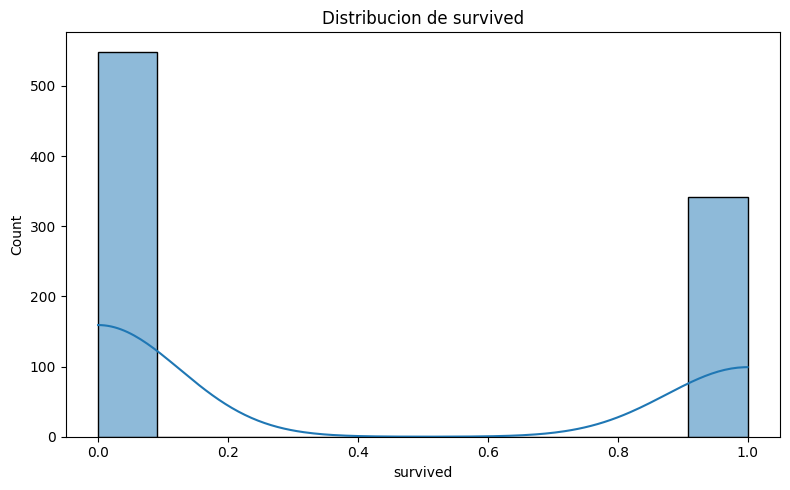

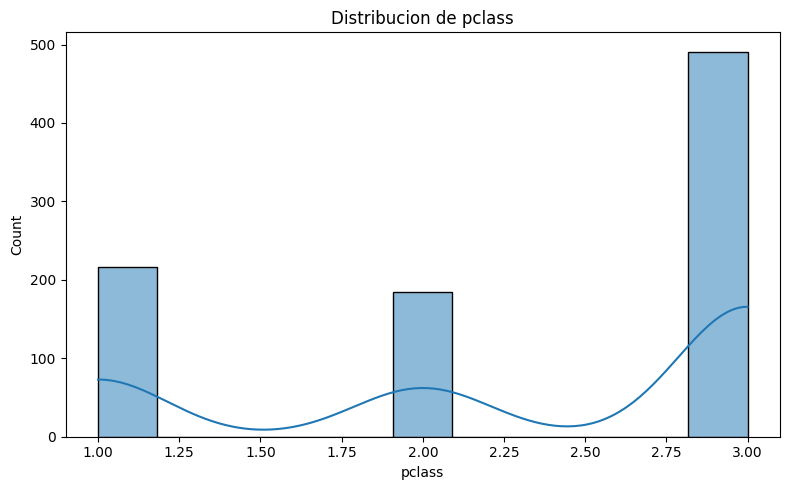

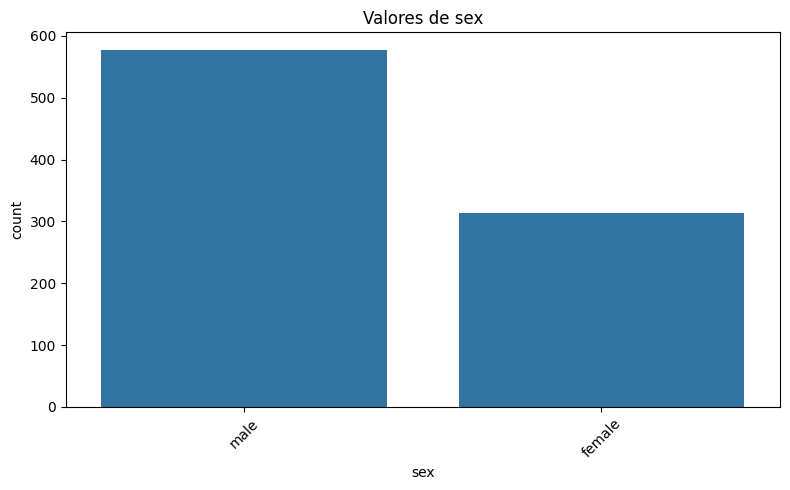

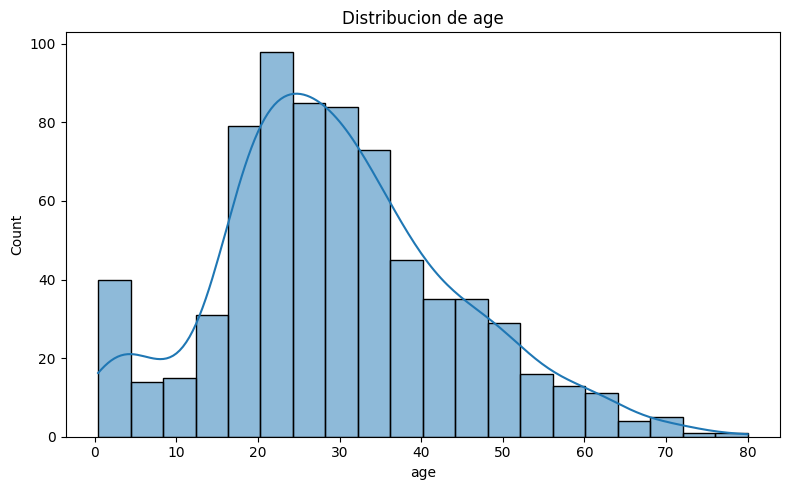

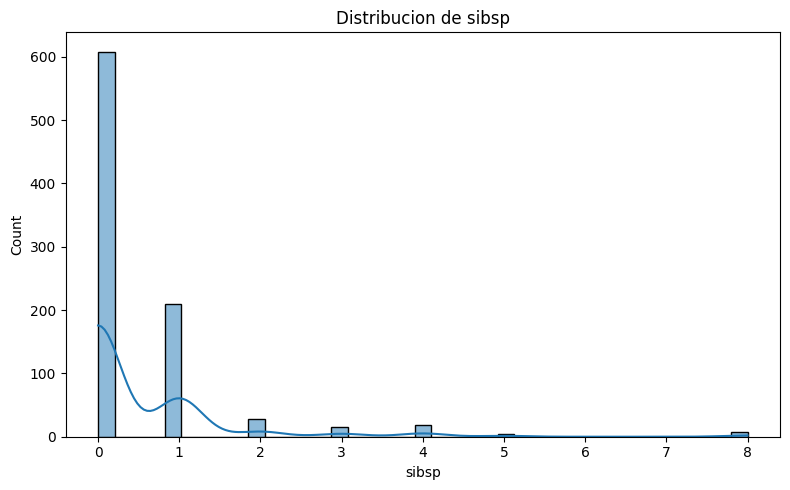

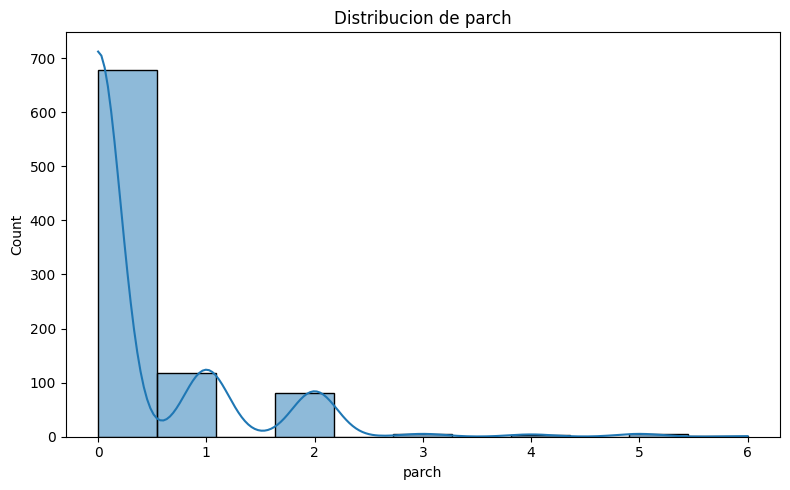

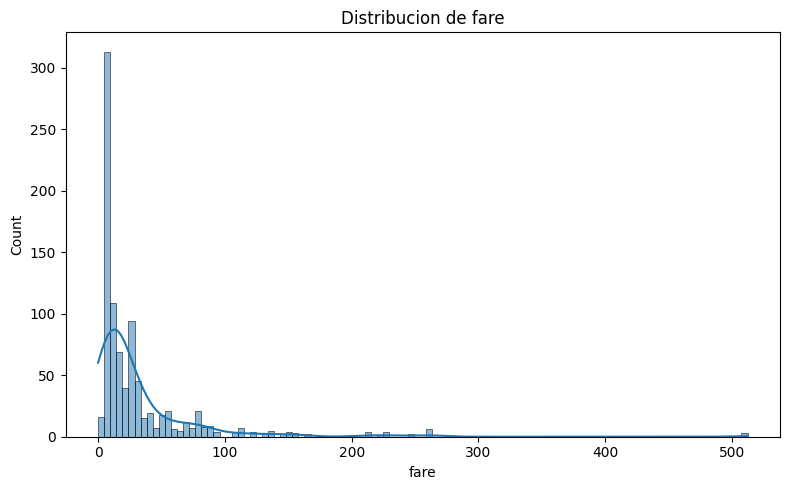

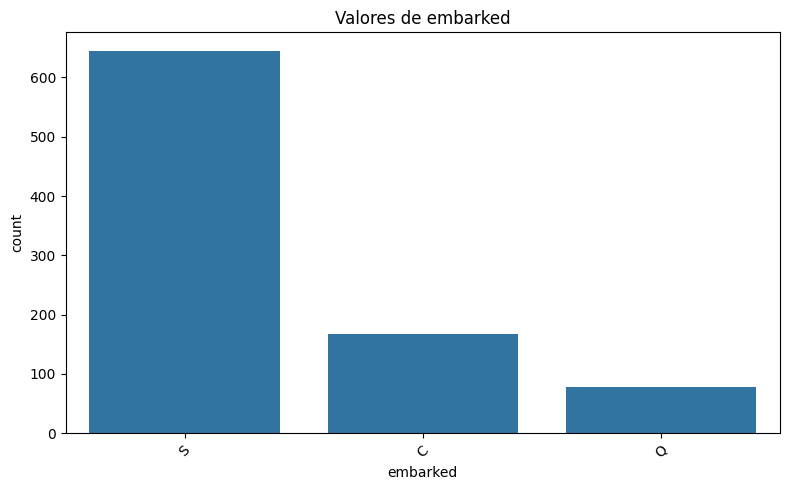

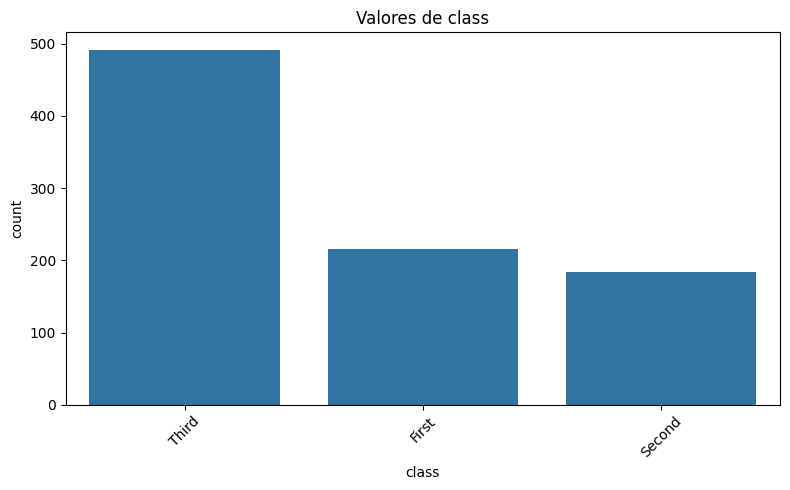

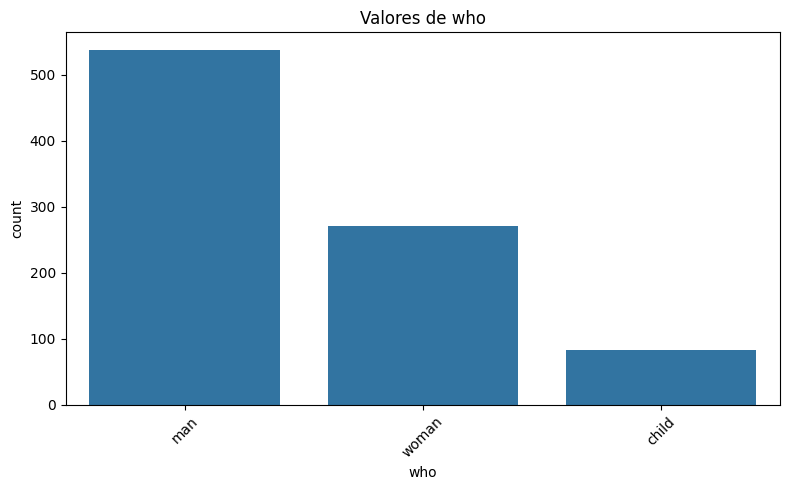

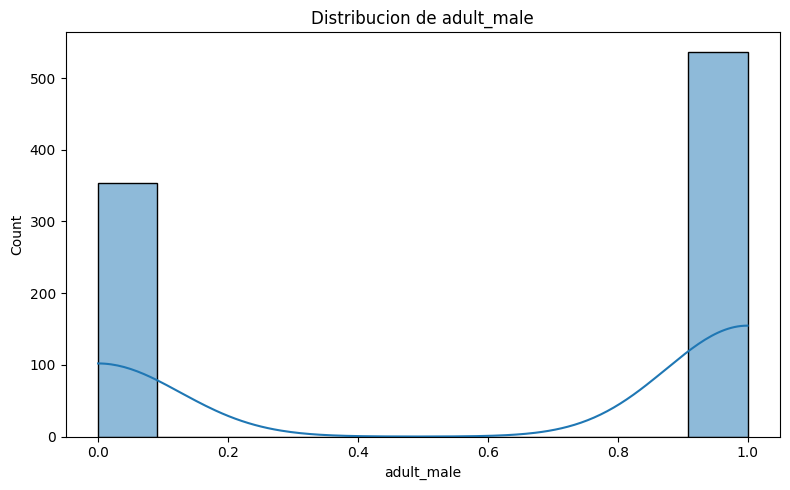

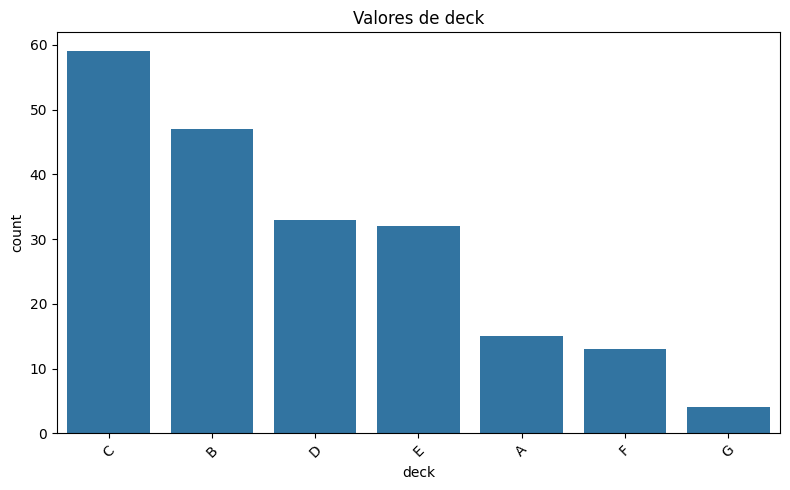

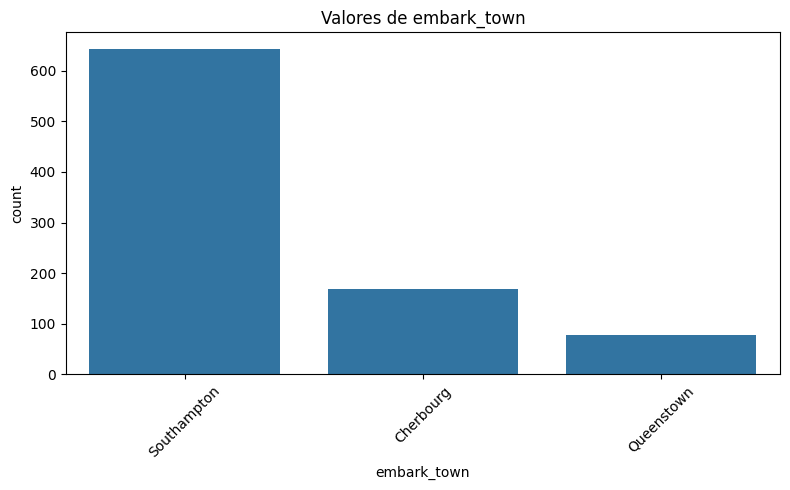

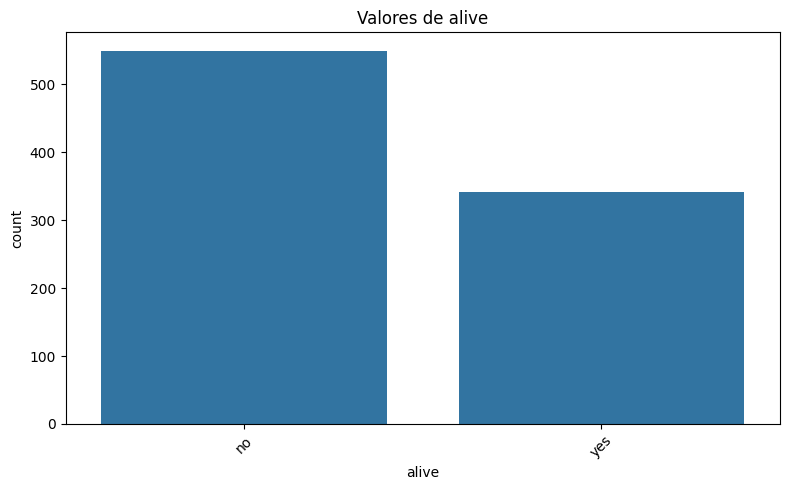

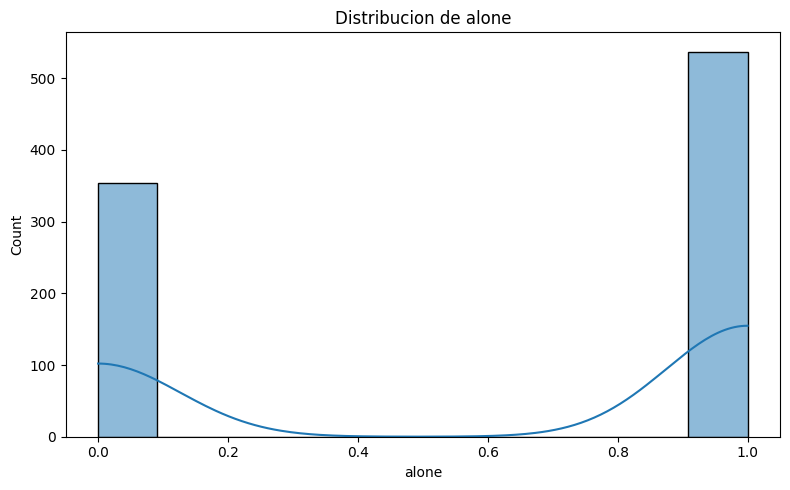

In [71]:
def exploracion_visual(df):

    for columna in df.columns:
        plt.figure(figsize=(8, 5))

        if pd.api.types.is_numeric_dtype(df[columna]):
            sns.histplot(data=df, x=columna, kde=True)
            plt.title("Distribucion de " + str(columna))

        elif pd.api.types.is_datetime64_any_dtype(df[columna]):
            df_temp = df.copy()
            df_temp["Anyo"] = df_temp[columna].dt.year
            sns.countplot(data=df_temp, x="Anyo")
            plt.title("Anyos de " + str(columna))

        else:
            sns.countplot(data=df, x=columna, order=df[columna].value_counts().index[:10])
            plt.title("Valores de " + str(columna))
            plt.xticks(rotation=45)

        nombre_grafico = "grafico_" + str(columna) + ".png"
        plt.tight_layout()
        plt.savefig(nombre_grafico)
        plt.show()
        plt.close()

df_ejemplo = sns.load_dataset("titanic")

exploracion_visual(df_ejemplo)


Ejercicio 2: Optimización de rutas (problema aplicado)

Algoritmo:
- Cargar la matriz de distancias y eliminar las ciudades insulares.
- Iniciar la ruta marcando la ciudad de origen como visitada.
- Iterar hasta llegar al destino. Buscar la ciudad no visitada que tenga la distancia mínima desde la posición actual.
- Sumar esa distancia al total, añadir la ciudad a la ruta y repetir el proceso.

In [72]:
def preparar_matriz(df):

    df_distancias = df.copy()
    if 'Unnamed: 0' in df_distancias.columns:
        df_distancias = df_distancias.set_index('Unnamed: 0')

    df_distancias.index = df_distancias.index.astype(str).str.strip()
    df_distancias.columns = df_distancias.columns.astype(str).str.strip()

    ciudades_a_eliminar = ["Las Palmas de Gran Canaria", "Palma"]
    df_distancias = df_distancias.drop(index=ciudades_a_eliminar, columns=ciudades_a_eliminar, errors="ignore")

    return df_distancias

def calcular_ruta(origen, destino, df_distancias):

    display(df_distancias)
    ruta = [origen]
    distancia_total = 0
    ciudad_actual = origen
    visitadas = [origen]

    while ciudad_actual != destino:

      opciones = df_distancias.loc[ciudad_actual].drop(index=visitadas)
      siguiente_ciudad = opciones.idxmin()
      distancia = opciones.min()
      distancia_total += distancia
      ruta.append(siguiente_ciudad)
      visitadas.append(siguiente_ciudad)
      ciudad_actual = siguiente_ciudad

    return ruta, distancia_total

def main_rutas(df):

    df_matriz = preparar_matriz(df)

    ciudad_origen = "Barcelona"
    ciudad_destino = "Vigo"

    ruta_optimizada, kilometros_totales = calcular_ruta(ciudad_origen, ciudad_destino, df_matriz)

    print("\nRuta a seguir:\n")
    print(ruta_optimizada)
    print("\nDistancia total recorrida:", kilometros_totales, "km")

main_rutas(distancias)

,Barcelona,Valencia,Sevilla,Zaragoza,Málaga,Murcia,Bilbao,Alicante,Córdoba,Valladolid,Vigo,Gijón,Hospitalet de Llobregat
Unnamed: 0,,,,,,,,,,,,,
Barcelona,NaN,303.0,831.0,256.0,770.0,471.0,469.0,407.0,711.0,576.0,908.0,686.0,7.0
Valencia,303.0,NaN,541.0,246.0,468.0,177.0,473.0,125.0,421.0,441.0,766.0,632.0,297.0
Sevilla,831.0,541.0,NaN,646.0,158.0,433.0,703.0,495.0,121.0,486.0,588.0,685.0,824.0
Zaragoza,256.0,246.0,646.0,NaN,628.0,408.0,246.0,368.0,535.0,320.0,652.0,444.0,250.0
Málaga,770.0,468.0,158.0,628.0,NaN,323.0,739.0,391.0,133.0,549.0,716.0,766.0,763.0
Murcia,471.0,177.0,433.0,408.0,323.0,NaN,606.0,69.0,320.0,510.0,800.0,726.0,465.0
Bilbao,469.0,473.0,703.0,246.0,739.0,606.0,NaN,583.0,618.0,232.0,486.0,223.0,465.0
Alicante,407.0,125.0,495.0,368.0,391.0,69.0,583.0,NaN,379.0,515.0,821.0,722.0,401.0
Córdoba,711.0,421.0,121.0,535.0,133.0,320.0,618.0,379.0,NaN,419.0,589.0,634.0,704.0



Ruta a seguir:

['Barcelona', 'Hospitalet de Llobregat', 'Zaragoza', 'Valencia', 'Alicante', 'Murcia', 'Córdoba', 'Sevilla', 'Málaga', 'Valladolid', 'Gijón', 'Bilbao', 'Vigo']

Distancia total recorrida: 2778.0 km
